# Topic 3: Introduction to Machine Learning using Python and Scikit-learn

This student-ready notebook uses the mobile-money transaction dataset in `Data/mobile_money_statements.csv` to build a binary fraud-classification model.

## Learning outcomes

By the end of this practical, you should be able to:

- identify the roles of NumPy, Pandas, Matplotlib and Scikit-learn;
- load, inspect and prepare a real-world dataset;
- distinguish features from a target variable;
- handle missing values and categorical variables;
- create and scale useful features;
- split data into training and testing sets;
- select, train and use a basic Logistic Regression model; and
- evaluate and interpret model predictions.

> **Important:** `manual_review_score` and `settlement_status` are post-outcome fields in this dataset. They are excluded from the predictive features because using them would leak information from the future into the model.

## Frame the problem before coding

Following the Week 1 ML lifecycle, start with the question rather than the algorithm:

- **Business objective:** identify suspicious mobile-money transactions for review.
- **ML task:** supervised binary classification because `is_fraud` has two classes.
- **Prediction time:** use only information available when the transaction is scored.
- **Success measure:** compare a model with a simple baseline using ROC-AUC, precision and recall; accuracy alone can be misleading when fraud is uncommon.
- **Constraints:** avoid target leakage, preserve an honest time order, and keep the workflow reproducible.

The complete lifecycle is iterative: **frame → get and explore data → prepare → train → evaluate → deploy → monitor → reframe**. This notebook demonstrates the first five steps.

## Why the split and baseline matter

For financial transactions, a random split can let the model learn from the future. We sort by transaction time and train on earlier transactions while testing on later ones. The test set is reserved for the final evaluation.

A majority-class baseline is the simplest reference: it always predicts the most common training class. With an uncommon fraud label, this baseline can have high accuracy while finding no fraud at all. Compare it with fraud recall and precision, not accuracy alone.


## 3.1 Machine-learning libraries

- **NumPy** provides fast numerical arrays and mathematical operations.
- **Pandas** provides labelled tables (`DataFrame`) for loading and transforming data.
- **Matplotlib** creates plots for understanding distributions and model results.
- **Scikit-learn** provides preprocessing tools, estimators, train/test splitting and evaluation metrics.

The next cell imports the libraries used in this practical.

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

%matplotlib inline
pd.set_option("display.max_columns", 40)


## Load and explore the data

The path below is relative to the repository root. If you open this notebook from another directory, update `DATA_PATH` accordingly.

In [2]:
DATA_PATH = "Data/mobile_money_statements.csv"
raw = pd.read_csv(DATA_PATH)
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
display(raw.head())
raw.info()

Rows: 183,600 | Columns: 18


,txn_id,msisdn,reg_id,account_name,region,segment,txn_time,txn_type,amount,gps_lat,gps_lon,agent_id,device_id,counterparty,balance_after,manual_review_score,settlement_status,is_fraud
0,TXN0102856,254700004022,NID101089,Joseph Mwangi,Kampala,retail,2026-06-30 14:24:19,send,"1,329/- Dr",NaN,NaN,AG1014,DV978723,CP6324,8123.0,0.061,settled,0
1,TXN0155490,254700013612,NID103658,Rehema Ndlovu,Mombasa,retail,"Jan 29, 2026 01:17 PM",send,289/- Dr,1.77470,34.70915,AG1084,DV616667,CP2831,6322.0,0.000,settled,0
2,TXN0019434,254700005862,nid101584,Mary Mutua,Arusha,retail,"Sep 16, 2025 12:55 AM",receive,"1,571/-",-3.74336,33.67018,AG1091,DV637734,CP167,15237.0,0.912,reversed,1
3,TXN0049426,254700009223,NID102493,Joseph Okoth,Dar es Salaam,retail,07/04/2026 11:21,send,599/- Dr,NaN,NaN,AG1047,DV666470,CP3382,3322.0,0.095,settled,0
4,TXN0013816,254700014760,nid103963,B. Ssentongo,Mwanza,retail,20/12/2025 11:05,cashout,"(1,307/-)",0.08284,29.02835,NaN,NaN,CP8428,2168.0,0.085,settled,0


<class 'pandas.DataFrame'>
RangeIndex: 183600 entries, 0 to 183599
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   txn_id               183600 non-null  str    
 1   msisdn               183600 non-null  int64  
 2   reg_id               183600 non-null  str    
 3   account_name         183600 non-null  str    
 4   region               183600 non-null  str    
 5   segment              183600 non-null  str    
 6   txn_time             183600 non-null  str    
 7   txn_type             183600 non-null  str    
 8   amount               183600 non-null  str    
 9   gps_lat              117117 non-null  float64
 10  gps_lon              117117 non-null  float64
 11  agent_id             158458 non-null  str    
 12  device_id            172744 non-null  str    
 13  counterparty         183600 non-null  str    
 14  balance_after        183600 non-null  float64
 15  manual_review_score  183600 

In [3]:
# Inspect data types, missing values, class balance and possible duplicate transactions.
summary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_count": raw.isna().sum(),
    "missing_percent": (raw.isna().mean() * 100).round(2),
})
display(summary)
print("Fraud class proportions:")
display(raw["is_fraud"].value_counts(normalize=True).rename("proportion"))

# Repeated transaction IDs can make copied records appear on both sides of a split.
duplicate_id_mask = raw["txn_id"].duplicated(keep=False)
duplicate_groups = raw.loc[duplicate_id_mask].groupby("txn_id", sort=False)
conflicting_duplicate_ids = int(
    duplicate_groups.nunique(dropna=False).gt(1).any(axis=1).sum()
)
print(f"Exact duplicate rows after the first copy: {raw.duplicated().sum():,}")
print(f"Extra rows with a repeated txn_id: {raw['txn_id'].duplicated().sum():,}")
print(f"Repeated txn_id groups with conflicting values: {conflicting_duplicate_ids:,}")

print("Fraud proportion by settlement status (diagnostic for target leakage):")
display(pd.crosstab(raw["settlement_status"], raw["is_fraud"], normalize="index").round(3))


,dtype,missing_count,missing_percent
txn_id,str,0,0.00
msisdn,int64,0,0.00
reg_id,str,0,0.00
account_name,str,0,0.00
region,str,0,0.00
segment,str,0,0.00
txn_time,str,0,0.00
txn_type,str,0,0.00
amount,str,0,0.00
gps_lat,float64,66483,36.21


Fraud class proportions:


is_fraud
0    0.915964
1    0.084036
Name: proportion, dtype: float64

Exact duplicate rows after the first copy: 3,600
Extra rows with a repeated txn_id: 3,600
Repeated txn_id groups with conflicting values: 0
Fraud proportion by settlement status (diagnostic for target leakage):


is_fraud,0,1
settlement_status,,
held,0.350,0.650
pending,1.000,0.000
reversed,0.000,1.000
settled,0.996,0.004


## 3.2 Prepare the data

### Identify the target and create features

`is_fraud` is the **target** (`y`) we want to predict. The remaining selected columns are **features** (`X`). Identifiers such as `txn_id`, names and phone numbers are excluded because they identify records rather than describe a transaction. The two post-outcome fields are also excluded to prevent target leakage.

The raw `txn_time` column contains three string formats: ISO timestamps, English month names with AM/PM, and day/month/year values with slashes. There are no blank timestamps in the source file, so any `NaT` created by parsing is a processing failure, not a missing value in the original data. The slash dates are treated as day/month/year; confirm that convention with the data provider when deploying this approach.


In [4]:
def parse_amount(value):
    """Convert values such as '1,329/- Dr' or '(227/-)' to signed numbers."""
    if pd.isna(value):
        return np.nan
    text = str(value).strip()
    negative = text.startswith("(") or re.search(r"\bDr\b", text, flags=re.IGNORECASE)
    number = re.sub(r"[^0-9.]", "", text)
    if not number:
        return np.nan
    amount = float(number)
    return -amount if negative else amount


def parse_mixed_datetime(series):
    """Parse the three documented timestamp formats without relying on inference."""
    text = series.astype("string").str.strip()
    parsed = pd.Series(pd.NaT, index=series.index, dtype="datetime64[ns]")
    formats = [
        ("ISO 24-hour with seconds", r"^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}$", "%Y-%m-%d %H:%M:%S"),
        ("English month name with AM/PM", r"^[A-Za-z]{3} \d{1,2}, \d{4} \d{2}:\d{2} [AP]M$", "%b %d, %Y %I:%M %p"),
        ("day/month/year 24-hour", r"^\d{1,2}/\d{1,2}/\d{4} \d{2}:\d{2}$", "%d/%m/%Y %H:%M"),
    ]
    parsed_counts = {}
    for label, pattern, date_format in formats:
        mask = parsed.isna() & text.str.match(pattern, na=False)
        candidates = pd.to_datetime(text.loc[mask], format=date_format, errors="coerce")
        parsed.loc[candidates.index] = candidates
        parsed_counts[label] = int(candidates.notna().sum())
    return parsed, parsed_counts


# Demonstrate the failure mode before fixing it. Raw txn_time has no nulls, but
# default inference uses one inferred format and can turn other valid formats into NaT.
default_timestamps = pd.to_datetime(raw["txn_time"], errors="coerce")
print(f"Blank txn_time values in the raw file: {raw['txn_time'].isna().sum():,}")
print(f"NaT values from default parsing: {default_timestamps.isna().sum():,}")

if conflicting_duplicate_ids:
    raise ValueError("Repeated txn_id values have conflicting records; investigate before deduplicating.")

data = raw.drop_duplicates(subset="txn_id", keep="first").copy()
print(f"Duplicate transaction rows removed: {len(raw) - len(data):,}")

data["txn_timestamp"], datetime_format_counts = parse_mixed_datetime(data["txn_time"])
print("Successfully parsed timestamps by format:")
print(datetime_format_counts)
print(f"Unparsed timestamps after explicit parsing: {data['txn_timestamp'].isna().sum():,}")

# The slash dates are interpreted as day/month/year, supported by values such as 20/12/2025.
# Ambiguous values such as 07/04/2026 still require confirmation from the source data contract.
data["amount_signed"] = data["amount"].map(parse_amount)
data["amount_abs"] = data["amount_signed"].abs()
data["transaction_hour"] = data["txn_timestamp"].dt.hour
data["transaction_day"] = data["txn_timestamp"].dt.dayofweek
data["is_weekend"] = data["transaction_day"].isin([5, 6]).astype(int)

print(f"Unparsed amounts: {data['amount_signed'].isna().sum():,}")


Blank txn_time values in the raw file: 0
NaT values from default parsing: 122,433
Duplicate transaction rows removed: 3,600


Successfully parsed timestamps by format:
{'ISO 24-hour with seconds': 59955, 'English month name with AM/PM': 60106, 'day/month/year 24-hour': 59939}
Unparsed timestamps after explicit parsing: 0


Unparsed amounts: 0


### Feature engineering and train/test split

The engineered amount and time features make the raw transaction fields usable by a model. We sort by time and reserve the latest 20% of transactions for testing. We do not stratify a chronological split: instead, we report the fraud rate in each period so that any change in class balance is visible.

The timestamp parser is checked before splitting. If a timestamp remains invalid, the next cell reports how many rows are omitted rather than silently losing them.


In [5]:
feature_columns = [
    "amount_abs",
    "gps_lat",
    "gps_lon",
    "transaction_hour",
    "transaction_day",
    "is_weekend",
    "txn_type",
    "region",
    "segment",
]
target_column = "is_fraud"

unparsed_timestamp_count = int(data["txn_timestamp"].isna().sum())
print(f"Rows excluded for an unparsed timestamp: {unparsed_timestamp_count:,}")
modeling_data = (
    data.dropna(subset=["txn_timestamp"])
    .sort_values("txn_timestamp", kind="stable")
    .copy()
)
X = modeling_data[feature_columns]
y = modeling_data[target_column]

split_index = int(len(modeling_data) * 0.80)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

train_start = modeling_data["txn_timestamp"].iloc[0]
train_end = modeling_data["txn_timestamp"].iloc[split_index - 1]
test_start = modeling_data["txn_timestamp"].iloc[split_index]
test_end = modeling_data["txn_timestamp"].iloc[-1]
train_reg_ids = set(modeling_data["reg_id"].iloc[:split_index])
test_reg_ids = set(modeling_data["reg_id"].iloc[split_index:])

print(f"Training rows: {len(X_train):,}")
print(f"Testing rows:  {len(X_test):,}")
print(f"Training period: {train_start} to {train_end}")
print(f"Testing period:  {test_start} to {test_end}")
print(f"Training fraud rate: {y_train.mean():.3f}")
print(f"Testing fraud rate:  {y_test.mean():.3f}")
print(f"Registered IDs present in both periods: {len(train_reg_ids & test_reg_ids):,}")
print(f"Test-period IDs not seen in training: {len(test_reg_ids - train_reg_ids):,}")


Rows excluded for an unparsed timestamp: 0


Training rows: 144,000
Testing rows:  36,000
Training period: 2025-02-06 00:46:00 to 2026-04-14 09:16:00
Testing period:  2026-04-14 09:26:42 to 2026-07-31 22:11:42
Training fraud rate: 0.084
Testing fraud rate:  0.085
Registered IDs present in both periods: 9,336
Test-period IDs not seen in training: 135


### Imputation, encoding and feature scaling

- Numeric missing values are replaced with the training median and then standardised.
- Categorical missing values are replaced with the most frequent training value and one-hot encoded.
- A `ColumnTransformer` applies the correct preparation to each column type.
- A `Pipeline` keeps preparation inside training, so test-set statistics do not influence imputers, scaling or encoding.

`balance_after` is excluded from the fraud features until its availability at the exact scoring time is confirmed. If it is calculated after a transaction is approved or posted, using it would be temporal leakage. GPS is missing for many rows; median imputation is a simple baseline, and a missing-location indicator is a useful follow-up experiment.


In [6]:
numeric_features = [
    "amount_abs",
    "gps_lat",
    "gps_lon",
    "transaction_hour",
    "transaction_day",
    "is_weekend",
]
categorical_features = ["txn_type", "region", "segment"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

## 3.3 Build a basic machine-learning model

Logistic Regression is an appropriate first classification algorithm because the target has two classes and the model is relatively easy to interpret. The model is initialised, trained with `.fit()`, and then used to generate predictions with `.predict()`.

In [7]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

# Training happens here: preprocessing and model fitting use X_train only.
model.fit(X_train, y_train)

predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

print("First five predicted classes:", predictions[:5])
print("First five fraud probabilities:", probabilities[:5].round(3))

First five predicted classes: [1 1 1 0 0]
First five fraud probabilities: [0.643 0.549 0.659 0.44  0.431]


### Establish a majority-class baseline

The baseline predicts the most common training class for every test transaction. It is a reference point, not a floor on every metric: it can achieve high accuracy while having zero fraud recall. The model may improve fraud detection and still have lower overall accuracy.


In [8]:
majority_class = y_train.mode().iloc[0]
baseline_predictions = np.full(len(y_test), majority_class)
print(f"Baseline class: {majority_class}")
print(f"Baseline accuracy: {accuracy_score(y_test, baseline_predictions):.3f}")
print(classification_report(y_test, baseline_predictions, target_names=["not fraud", "fraud"], zero_division=0))

Baseline class: 0
Baseline accuracy: 0.915
              precision    recall  f1-score   support

   not fraud       0.91      1.00      0.96     32930
       fraud       0.00      0.00      0.00      3070

    accuracy                           0.91     36000
   macro avg       0.46      0.50      0.48     36000
weighted avg       0.84      0.91      0.87     36000



### Evaluate model performance

Accuracy is shown for comparison, but fraud is the minority class. We therefore also report fraud precision and recall, ROC-AUC, and average precision (a precision-recall summary). The reported class predictions use Logistic Regression's default 0.5 threshold. That threshold is only a demonstration: choose a real operating threshold using validation data and the cost or review capacity of the business, never by tuning on the final test set.


Accuracy at threshold 0.5: 0.639
ROC-AUC:                  0.612
Average precision:        0.130
Test fraud prevalence:    0.085

Classification report at the default 0.5 threshold:


              precision    recall  f1-score   support

   not fraud       0.93      0.65      0.77     32930
       fraud       0.12      0.50      0.19      3070

    accuracy                           0.64     36000
   macro avg       0.53      0.58      0.48     36000
weighted avg       0.86      0.64      0.72     36000



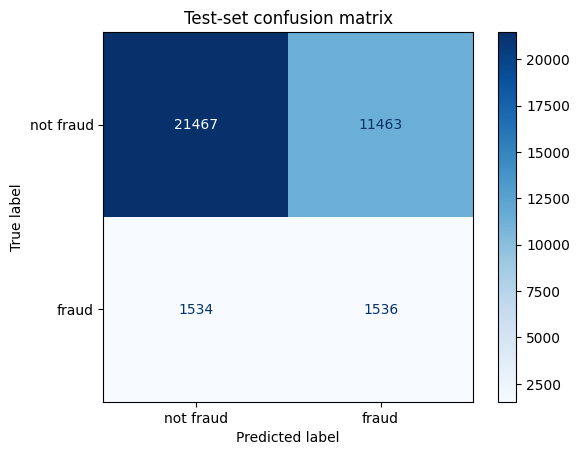

In [9]:
print(f"Accuracy at threshold 0.5: {accuracy_score(y_test, predictions):.3f}")
print(f"ROC-AUC:                  {roc_auc_score(y_test, probabilities):.3f}")
print(f"Average precision:        {average_precision_score(y_test, probabilities):.3f}")
print(f"Test fraud prevalence:    {y_test.mean():.3f}")
print("\nClassification report at the default 0.5 threshold:")
print(classification_report(y_test, predictions, target_names=["not fraud", "fraud"], zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    display_labels=["not fraud", "fraud"],
    cmap="Blues",
)
plt.title("Test-set confusion matrix")
plt.show()


### Interpret predictions

A model probability is not a guarantee or necessarily a calibrated probability. In particular, `class_weight="balanced"` changes the class penalties during fitting, so treat the scores as ranking signals until calibration has been checked on validation data. The table below compares actual labels, predicted labels and scores for example test transactions.


In [10]:
examples = X_test.head(10).copy()
examples["actual_fraud"] = y_test.loc[examples.index]
examples["predicted_fraud"] = predictions[:10]
examples["fraud_probability"] = probabilities[:10].round(3)
display(examples[["amount_abs", "txn_type", "region", "actual_fraud", "predicted_fraud", "fraud_probability"]])

,amount_abs,txn_type,region,actual_fraud,predicted_fraud,fraud_probability
135579,3035.0,cashout,Eldoret,0,1,0.643
165249,758.0,send,Eldoret,0,1,0.549
101159,1892.0,cashout,Mombasa,0,1,0.659
120494,528.0,receive,Mwanza,0,0,0.440
82072,149.0,airtime,Eldoret,0,0,0.431
57519,55.0,airtime,Nakuru,0,0,0.425
117902,2915.0,receive,Kampala,0,0,0.437
7438,90.0,airtime,Arusha,1,0,0.421
40598,3101.0,send,Eldoret,0,1,0.550
21212,518.0,send,Arusha,0,1,0.532


In [11]:
# Coefficients describe conditional associations in this fitted linear model; they are not causal effects.
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
coefficients = model.named_steps["classifier"].coef_[0]
effects = pd.Series(coefficients, index=feature_names).sort_values()

print("Features with the most negative fitted coefficients:")
display(effects.head(10))
print("Features with the most positive fitted coefficients:")
display(effects.tail(10).sort_values(ascending=False))


Features with the most negative fitted coefficients:


categorical__txn_type_cashin    -0.226704
categorical__txn_type_receive   -0.204740
categorical__txn_type_airtime   -0.203263
categorical__txn_type_bill      -0.196555
categorical__txn_type_paybill   -0.183943
numeric__transaction_hour       -0.176539
categorical__region_Arusha      -0.068009
categorical__segment_agent      -0.065557
categorical__region_Nakuru      -0.050411
categorical__region_Jinja       -0.036218
dtype: float64

Features with the most positive fitted coefficients:


categorical__txn_type_cashout    0.660988
categorical__txn_type_send       0.267620
categorical__region_Nairobi      0.076762
categorical__region_Mombasa      0.051368
numeric__transaction_day         0.011909
categorical__region_Mwanza       0.011620
numeric__amount_abs              0.003184
numeric__gps_lat                -0.003057
numeric__is_weekend             -0.005007
categorical__region_Kampala     -0.005836
dtype: float64

## Alternative target: `monthly_inflow_kes` (regression)

If the target is a numeric amount such as `monthly_inflow_kes`, the problem changes from **classification** to **regression**. The target is derived as each customer's monthly sum of `receive` and `cashin` amounts. Predictors are lagged values from the previous observed active month; inactive calendar months are not filled in, so a lag can span more than one calendar month. Region and segment are also lagged to ensure they were known before the target month.

This example uses a chronological month split. A random row split could put later months in training and earlier months in testing, overstating how well the model forecasts the future.


In [12]:
monthly_source = data.dropna(subset=["txn_timestamp"]).copy()
monthly_source["month"] = monthly_source["txn_timestamp"].dt.to_period("M")

inflow_types = ["receive", "cashin"]
monthly_source["inflow_amount"] = monthly_source["amount_abs"].where(
    monthly_source["txn_type"].isin(inflow_types), 0
)

monthly = (
    monthly_source.groupby(["reg_id", "month"], as_index=False)
    .agg(
        monthly_inflow_kes=("inflow_amount", "sum"),
        transaction_count=("txn_id", "count"),
        average_balance=("balance_after", "mean"),
        region=("region", "last"),
        segment=("segment", "last"),
    )
    .sort_values(["reg_id", "month"])
)

lagged_columns = [
    "monthly_inflow_kes",
    "transaction_count",
    "average_balance",
    "region",
    "segment",
]
for column in lagged_columns:
    monthly[f"previous_{column}"] = monthly.groupby("reg_id")[column].shift(1)

regression_data = monthly.dropna(
    subset=[
        "previous_monthly_inflow_kes",
        "previous_transaction_count",
        "previous_average_balance",
        "previous_region",
        "previous_segment",
    ]
).copy()
display(regression_data.head())
print(f"Customer-month rows: {len(regression_data):,}")


,reg_id,month,monthly_inflow_kes,transaction_count,average_balance,region,segment,previous_monthly_inflow_kes,previous_transaction_count,previous_average_balance,previous_region,previous_segment
1,NID100000,2026-04,3721.0,1,3211.0,Mwanza,agent,0.0,1.0,5706.0,Mwanza,agent
3,NID100001,2025-04,0.0,1,143.0,Kampala,retail,0.0,1.0,29580.0,Kampala,retail
4,NID100001,2025-06,0.0,1,1958.0,Kampala,retail,0.0,1.0,143.0,Kampala,retail
5,NID100001,2025-09,0.0,1,5417.0,Kampala,retail,0.0,1.0,1958.0,Kampala,retail
6,NID100001,2025-11,0.0,2,7954.5,Kampala,retail,0.0,1.0,5417.0,Kampala,retail


Customer-month rows: 88,202


### Build and evaluate a regression model

For regression, use metrics designed for numeric errors: **MAE** is the average absolute error in KES, **RMSE** penalises larger errors more strongly, and **R²** compares with a mean-only prediction. We compare the model against a mean baseline and test on later months.


In [13]:
regression_numeric = [
    "previous_monthly_inflow_kes",
    "previous_transaction_count",
    "previous_average_balance",
]
regression_categorical = ["previous_region", "previous_segment"]
regression_features = regression_numeric + regression_categorical

unique_months = sorted(regression_data["month"].unique())
split_position = int(len(unique_months) * 0.80)
if not 0 < split_position < len(unique_months):
    raise ValueError("Need at least two distinct months for a chronological regression split.")
cutoff_month = unique_months[split_position]
train_mask = regression_data["month"] < cutoff_month

grouped_features = regression_data[regression_features]
X_reg_train = grouped_features.loc[train_mask]
X_reg_test = grouped_features.loc[~train_mask]
y_reg_train = regression_data.loc[train_mask, "monthly_inflow_kes"]
y_reg_test = regression_data.loc[~train_mask, "monthly_inflow_kes"]
print(f"Training target months: {regression_data.loc[train_mask, 'month'].min()} to {regression_data.loc[train_mask, 'month'].max()}")
print(f"Testing target months:  {regression_data.loc[~train_mask, 'month'].min()} to {regression_data.loc[~train_mask, 'month'].max()}")
print(f"Regression training rows: {len(X_reg_train):,} | testing rows: {len(X_reg_test):,}")

regression_preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), regression_numeric),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
    ]), regression_categorical),
])

regression_model = Pipeline([
    ("preprocessor", regression_preprocessor),
    ("regressor", LinearRegression()),
])
regression_model.fit(X_reg_train, y_reg_train)
inflow_predictions = regression_model.predict(X_reg_test)

regression_baseline = DummyRegressor(strategy="mean")
regression_baseline.fit(X_reg_train, y_reg_train)
baseline_predictions = regression_baseline.predict(X_reg_test)

def regression_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
    }

print("Mean baseline:", regression_metrics(y_reg_test, baseline_predictions))
print("Linear regression:", regression_metrics(y_reg_test, inflow_predictions))


Training target months: 2025-03 to 2026-03
Testing target months:  2026-04 to 2026-07
Regression training rows: 65,961 | testing rows: 22,241


Mean baseline: {'MAE': 1461.4396280660649, 'RMSE': np.float64(2019.3036819857452), 'R2': -0.0003110703846354035}
Linear regression: {'MAE': 1435.673767306767, 'RMSE': np.float64(1995.6069191179654), 'R2': 0.02302870664561807}


The original fraud example remains a classification problem because `is_fraud` is a 0/1 class label. The `monthly_inflow_kes` example is a regression problem because its target is a continuous numeric amount. Choose the estimator, predictions and metrics to match the target type.

## Practical exercise

Fork this repository and work on a branch of your own. Then extend this notebook:

1. Plot the distribution of `amount_abs` for fraud and non-fraud transactions.
2. Add one defensible feature, such as a missing-GPS indicator or a log-transformed amount, and compare average precision and ROC-AUC.
3. Train a Decision Tree or Random Forest in a second pipeline.
4. Compare the models using fraud precision, recall, F1-score, average precision and ROC-AUC.
5. Choose an operating threshold on validation data and explain how it changes fraud recall, false positives and review volume.
6. Check whether a group-aware evaluation is needed for the intended deployment population (new customers versus future transactions from known customers).

Do not add `manual_review_score` or `settlement_status` to the predictive features: both are recorded after the outcome and would make the evaluation misleading. Also confirm that every proposed feature is available at the moment a transaction would be scored.


## Lesson 1 check: what this notebook demonstrates

| Lesson 1 idea | Evidence in this practical |
| --- | --- |
| Frame the task and choose a baseline | Fraud is a supervised binary-classification task; the majority baseline exposes why accuracy alone fails. |
| Prepare and verify data | Mixed timestamp formats, duplicate transaction IDs, missing GPS, and post-outcome fields are inspected explicitly. |
| Protect the evaluation | Fraud transactions are tested on a later time period; preprocessing is fitted inside a training pipeline; regression is also split by month. |
| Check generalization limits | Class prevalence and customer overlap are reported. The fraud split measures future transactions for a population that mostly overlaps with training customers. |
| Match metrics to the objective | Precision, recall, ROC-AUC and average precision supplement accuracy; the operating threshold still needs business costs or review capacity. |

This is an offline teaching pipeline, not a deployed ML system. A production decision would still need confirmed feature availability, threshold and cost review, fairness checks, monitoring for data or concept drift, and reproducible packaging.
